# Prognoza ludności klastrów Warszawy 2025–2036

Model dla klastra *h* (heksagon H3, ~0,7 km²) w dzielnicy *d*:

$$P_h(t) = \underbrace{P_h(2025)\,(1+\text{dryf}_d)^{t-2025}}_{\text{zabudowa istniejąca}} + \underbrace{\textstyle\sum \text{mieszkania}\cdot\text{realizacja}\cdot\text{os./mieszkanie}\cdot\text{zasiedlenie}(t)}_{\text{nowe budynki z pozwoleń GUNB}}$$

* **Nowe budynki** — pozwolenia GUNB 2016–2026, zasiedlane 2–4 lata po decyzji; po wyczerpaniu rejestru „wirtualne pozwolenia” w tempie z lat 2022–2025 (słabnące o 10%/rok).
* **Zabudowa istniejąca** — w starych osiedlach ludności ubywa (mniejsze gospodarstwa, przeprowadzki do nowych mieszkań).
* **Parametry z danych**, nie z założeń: kalibracja na spisach NSP 2011 → 2021 i mieszkaniach oddanych do użytkowania (GUS).
* **Kontrola**: suma miasta vs oficjalna prognoza GUS 2023–2060.

Logika: [`mapping/prognoza_ludnosci.py`](mapping/prognoza_ludnosci.py). Wynik: `dane/ludnosc/prognoza_ludnosci.csv`.

In [ ]:
# Notebook leży w notebooki/ — przechodzimy do katalogu głównego repo,
# żeby działały ścieżki "dane/..." i import modułów z mapping/.
import os
from pathlib import Path

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "dane").is_dir() and (p / "mapping").is_dir())
os.chdir(ROOT)

In [1]:
import sys
sys.path.insert(0, "mapping")
import importlib
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import prognoza_ludnosci as pl
importlib.reload(pl)

# Styl wykresów: cienkie linie, stonowane osie, jedna oś Y.
INK, INK2, MUTED, GRID, SURF = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#fcfcfb"
BLUE, ORANGE, AQUA, RED = "#2a78d6", "#eb6834", "#1baf7a", "#e34948"
plt.rcParams.update({"figure.facecolor": SURF, "axes.facecolor": SURF, "axes.edgecolor": "#c3c2b7",
                     "axes.labelcolor": INK2, "xtick.color": MUTED, "ytick.color": MUTED, "axes.grid": True,
                     "grid.color": GRID, "grid.linewidth": 0.6, "axes.spines.top": False, "axes.spines.right": False,
                     "font.size": 10, "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
                     "lines.linewidth": 2})
fmt = lambda x: f"{x:,.0f}".replace(",", " ")

inputs = pl.load_inputs()
cal = inputs["calibration"]
print(f"klastrów: {len(inputs['hexes'])}, pozwoleń GUNB: {len(inputs['permits'])}")

klastrów: 848, pozwoleń GUNB: 1767


## 1. Rejestr pozwoleń GUNB vs GUS

Rejestr z lat 2016–2021 jest niekompletny (część decyzji nie trafiła do systemu), więc każdy rok skalujemy do liczby mieszkań z pozwoleniami według GUS.

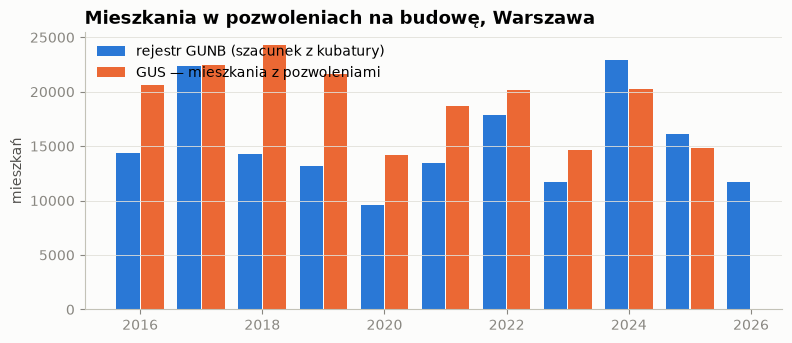

rok,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
mnożnik rejestru,1.43,1.0,1.7,1.64,1.47,1.39,1.13,1.25,1.0,1.0,1.0


In [2]:
reg = inputs["permits"].groupby("rok")["n_flats"].sum()
gus = inputs["gus_permits"].reindex(reg.index)
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.bar(reg.index - 0.2, reg, width=0.38, color=BLUE, label="rejestr GUNB (szacunek z kubatury)")
ax.bar(gus.index + 0.2, gus, width=0.38, color=ORANGE, label="GUS — mieszkania z pozwoleniami")
ax.set_title("Mieszkania w pozwoleniach na budowę, Warszawa"); ax.set_ylabel("mieszkań")
ax.legend(frameon=False, loc="upper left"); ax.grid(axis="x", visible=False)
plt.show()
inputs["permit_scale"].round(2).rename("mnożnik rejestru").to_frame().T

## 2. Dlaczego nie kalibrujemy do rocznych danych GUS

Roczna „ludność” GUS opiera się na meldunkach. W latach 2021–2025 oddano w Warszawie kilkadziesiąt tysięcy mieszkań, a zameldowanych prawie nie przybyło — najemcy bez meldunku i migranci są dla rejestru niewidoczni, ale dla komunikacji miejskiej są realnymi pasażerami. Spisy (NSP) liczą faktycznych mieszkańców, więc to na nich kalibrujemy.

In [3]:
o = inputs["completed"].loc[pl.WARSAW_TOTAL]
d = inputs["districts"]
done_21_25 = o.loc[2021:2025].sum()
reg_change = d["ludnosc_gus_2025"].sum() - d["ludnosc_gus_2021"].sum()
print(f"mieszkania oddane 2021–2025: {fmt(done_21_25)}")
print(f"zmiana ludności GUS (meldunki) 2021→2025: {fmt(reg_change)}")
print(f"=> {reg_change / done_21_25:.2f} zameldowanej osoby na nowe mieszkanie")

mieszkania oddane 2021–2025: 84 802
zmiana ludności GUS (meldunki) 2021→2025: 3 673
=> 0.04 zameldowanej osoby na nowe mieszkanie


## 3. Kalibracja na spisach 2011 → 2021

Dla 18 dzielnic: $\Delta P_d = a \cdot \text{oddane}_d + b \cdot P_d(2011)$.
*a* = ilu mieszkańców przynosi nowe mieszkanie, *b* = jak szybko ubywa ludzi w istniejącej zabudowie.
Leave-one-out: każdą dzielnicę przewidujemy z parametrów dopasowanych bez niej.

osoby na nowe mieszkanie a = 2.29
dryf zabudowy istniejącej  = -1.64% rocznie
realizacja pozwoleń        = 0.95 (mieszkania oddane / pozwolenia sprzed 3 lat)
R² = 0.66, leave-one-out R² = 0.34


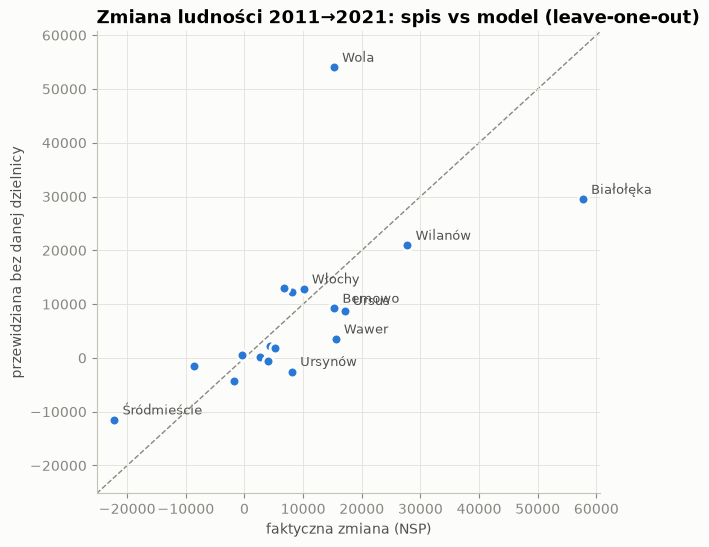

,gus_2011,gus_2021,oddane,zmiana,pred,pred_loo,dryf_roczny_proc
dzielnica,,,,,,,
Śródmieście,128880,106672,2528,-22208,-13789,-11558,-1.83
Praga-Północ,74268,65658,4184,-8610,-1688,-1422,-1.92
Ochota,79938,78083,3452,-1855,-4229,-4363,-1.55
Bielany,136878,136431,9241,-447,398,499,-1.65
Rembertów,25954,28588,1820,2634,230,221,-1.38
Wesoła,21665,25628,1218,3963,-497,-511,-1.09
Mokotów,211532,215926,15176,4394,2671,2124,-1.61
Targówek,117451,122607,8697,5156,2104,1866,-1.56
Żoliborz,42656,49397,8358,6741,12696,12919,-2.07


In [4]:
print(f"osoby na nowe mieszkanie a = {cal['os_na_mieszkanie']:.2f}")
print(f"dryf zabudowy istniejącej  = {100 * cal['dryf_miasta']:.2f}% rocznie")
print(f"realizacja pozwoleń        = {cal['realizacja']:.2f} (mieszkania oddane / pozwolenia sprzed {pl.REALIZATION_LAG} lat)")
print(f"R² = {cal['r2']:.2f}, leave-one-out R² = {cal['r2_loo']:.2f}")

t = cal["tabela"]
fig, ax = plt.subplots(figsize=(6.5, 6))
lim = [t[["zmiana", "pred_loo"]].min().min() - 3000, t[["zmiana", "pred_loo"]].max().max() + 3000]
ax.plot(lim, lim, color=MUTED, lw=1, ls="--", zorder=1)
ax.scatter(t["zmiana"], t["pred_loo"], s=60, color=BLUE, edgecolor=SURF, linewidth=2, zorder=3)
for name, r in t.iterrows():
    if abs(r["zmiana"]) > 9000 or abs(r["zmiana"] - r["pred_loo"]) > 9000:
        ax.annotate(name, (r["zmiana"], r["pred_loo"]), xytext=(6, 4), textcoords="offset points", color=INK2, fontsize=9)
ax.set_xlim(lim); ax.set_ylim(lim)
ax.set_title("Zmiana ludności 2011→2021: spis vs model (leave-one-out)")
ax.set_xlabel("faktyczna zmiana (NSP)"); ax.set_ylabel("przewidziana bez danej dzielnicy")
plt.show()
t[["gus_2011", "gus_2021", "oddane", "zmiana", "pred", "pred_loo"]].round(0).astype(int).assign(
    dryf_roczny_proc=(100 * t["dryf_roczny"]).round(2)).sort_values("zmiana")

## 4. Prognoza i kontrola z prognozą GUS

Scenariusze: **niski** (realizacja ×0,85, os./mieszkanie ×0,85), **bazowy**, **wysoki** (×1,05, ×1,15).
Wariant **A** to rozłożenie przyrostu z prognozy GUS proporcjonalnie do nowych mieszkań (bez spadku w starej zabudowie) — dla porównania.

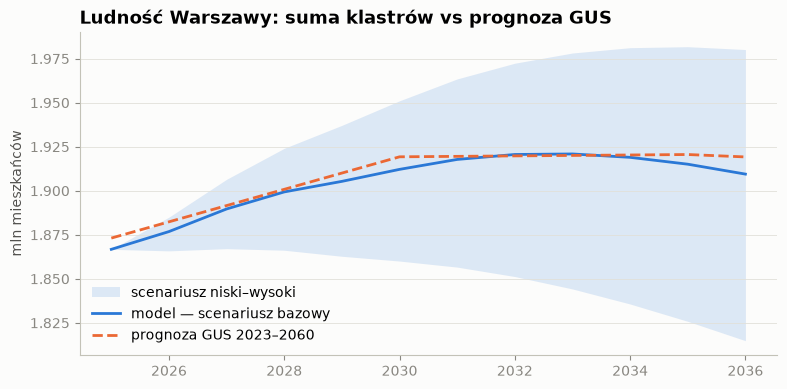

,niski,bazowy,wysoki,wariant GUS (A),prognoza GUS
2025,1866736,1866736,1866736,1866736,1873127
2028,1866228,1899339,1924098,1900813,1900813
2031,1856646,1917782,1963496,1919531,1919531
2033,1844236,1920891,1978210,1920050,1920050
2036,1814868,1909453,1980179,1919199,1919199


In [5]:
out, totals = pl.build_output(inputs)
years = pl.YEARS
fig, ax = plt.subplots(figsize=(9, 4.2))
ax.fill_between(years, totals.loc[years, "niski"] / 1e6, totals.loc[years, "wysoki"] / 1e6, color=BLUE, alpha=0.15,
                lw=0, label="scenariusz niski–wysoki")
ax.plot(years, totals.loc[years, "bazowy"] / 1e6, color=BLUE, label="model — scenariusz bazowy")
ax.plot(years, totals.loc[years, "prognoza GUS"] / 1e6, color=ORANGE, ls="--", label="prognoza GUS 2023–2060")
ax.set_title("Ludność Warszawy: suma klastrów vs prognoza GUS"); ax.set_ylabel("mln mieszkańców")
ax.legend(frameon=False, loc="lower left"); ax.grid(axis="x", visible=False)
plt.show()
totals.loc[[2025, 2028, 2031, 2033, 2036]]

## 5. Gdzie przybędzie, a gdzie ubędzie mieszkańców

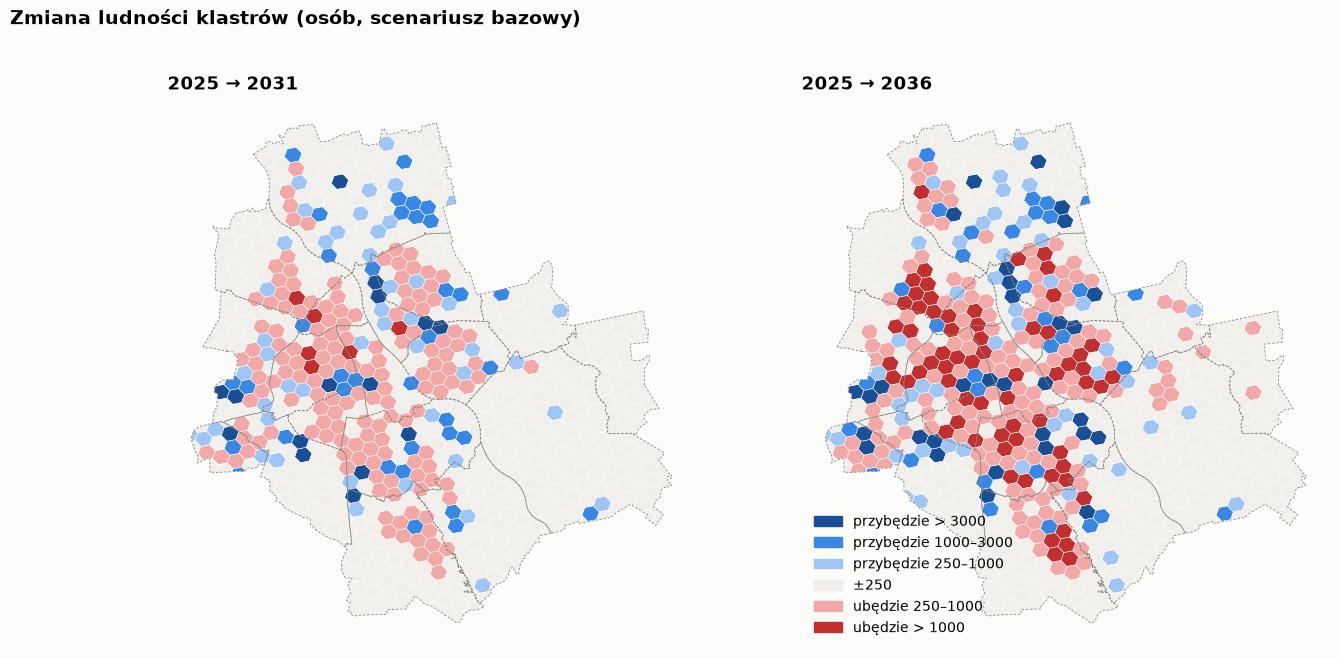

,pop_2025,pop_2031,pop_2036,zmiana_proc
dzielnica,,,,
Ochota,83914,77700,72963,-13.1
Żoliborz,57020,53560,50162,-12.0
Bielany,135671,127793,120822,-10.9
Wesoła,27218,25799,24736,-9.1
Targówek,119913,116588,112670,-6.0
Ursynów,147845,146114,142260,-3.8
Wola,135193,135226,130011,-3.8
Praga-Południe,184377,181870,178627,-3.1
Wawer,91537,90298,88898,-2.9


In [6]:
hexes = gpd.read_file(pl.ROOT / "dane/klastry/kontury_400m/warszawa_h3_400m_pelna.geojson")[["h3", "geometry"]]
g = hexes.merge(out, on="h3").to_crs(2180)
dz = gpd.read_file(pl.EXTERNAL_DIR / "warszawa_dzielnice.geojson").to_crs(2180)

bins = [-1e9, -1000, -250, 250, 1000, 3000, 1e9]
cols = ["#c22f2f", "#f2a8a6", "#f0efec", "#9ec5f4", "#3987e5", "#184f95"]
labs = ["ubędzie > 1000", "ubędzie 250–1000", "±250", "przybędzie 250–1000", "przybędzie 1000–3000", "przybędzie > 3000"]
from matplotlib.patches import Patch
fig, axes = plt.subplots(1, 2, figsize=(15, 7.5))
for ax, col, title in [(axes[0], "dP_2031", "2025 → 2031"), (axes[1], "dP_2036", "2025 → 2036")]:
    k = pd.cut(g[col], bins, labels=False)
    g.plot(ax=ax, color=[cols[int(i)] for i in k], edgecolor=SURF, linewidth=0.4)
    dz.boundary.plot(ax=ax, color=MUTED, linewidth=0.6, linestyle=(0, (3, 2)))
    ax.set_axis_off(); ax.set_title(title)
fig.suptitle("Zmiana ludności klastrów (osób, scenariusz bazowy)", x=0.02, ha="left", fontweight="bold", fontsize=14)
axes[1].legend(handles=[Patch(color=c, label=l) for c, l in zip(cols, labs)][::-1], frameon=False, loc="lower left")
plt.show()

out.groupby("dzielnica")[["pop_2025", "pop_2031", "pop_2036"]].sum().assign(
    zmiana_proc=lambda d: (100 * (d.pop_2036 / d.pop_2025 - 1)).round(1)).sort_values("zmiana_proc")

## 6. Przykładowe klastry

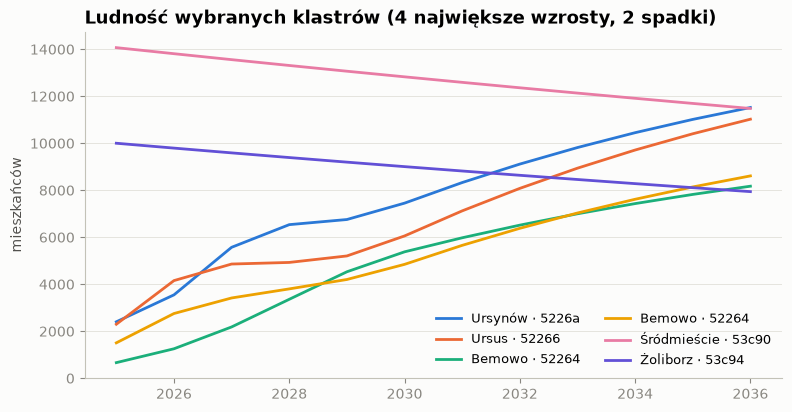

In [7]:
top = out.nlargest(4, "dP_2036")["h3"].tolist() + out.nsmallest(2, "dP_2036")["h3"].tolist()
o2 = out.set_index("h3")
fig, ax = plt.subplots(figsize=(9, 4.5))
palette = [BLUE, ORANGE, AQUA, "#eda100", "#e87ba4", "#6250d6"]
for color, h in zip(palette, top):
    series = [o2.loc[h, "pop_2025"]] + [o2.loc[h, f"pop_{t}"] for t in years[1:]]
    ax.plot(years, series, color=color, label=f"{o2.loc[h, 'dzielnica']} · {h[4:9]}")
ax.set_title("Ludność wybranych klastrów (4 największe wzrosty, 2 spadki)"); ax.set_ylabel("mieszkańców")
ax.legend(frameon=False, ncol=2, fontsize=9); ax.grid(axis="x", visible=False)
plt.show()

## 7. Zapis

In [8]:
out.to_csv(pl.OUT, index=False, encoding="utf-8-sig")
print(pl.OUT, out.shape)
out.head()

/Users/patrykbasiak/optymalna-warszawa/3_TheBills_OptymalnaWarszawa/dane/ludnosc/prognoza_ludnosci.csv (848, 41)


,h3,dzielnica,pop_2025,pop_2026_niski,pop_2027_niski,pop_2028_niski,pop_2029_niski,pop_2030_niski,pop_2031_niski,pop_2032_niski,...,pop_2032_wysoki,pop_2033_wysoki,pop_2034_wysoki,pop_2035_wysoki,pop_2036_wysoki,pop_2036_wariant_gus,mieszkania_w_budowie,dryf_roczny_proc,dP_2031,dP_2036
0,881f53d9ebfffff,Białołęka,218,216,213,211,208,206,204,201,...,201,199,197,195,193,218,0,-1.12,-14,-25
1,881f53d9e3fffff,Białołęka,75,74,73,73,72,71,70,69,...,69,69,68,67,66,75,0,-1.12,-5,-9
2,881f53d9ddfffff,Białołęka,314,310,307,304,300,297,293,290,...,290,287,284,280,277,314,0,-1.12,-21,-37
3,881f53d9d7fffff,Białołęka,554,548,542,536,530,524,518,512,...,512,506,500,495,489,554,0,-1.12,-36,-65
4,881f53d9d5fffff,Białołęka,49,48,48,47,47,46,46,45,...,45,45,44,44,43,49,0,-1.12,-3,-6
